[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hbprosper/mlinphysics/blob/main/Labs/05.PINN/tutorial_PINN_SIR_y_march.ipynb)

# Physics Informed Neural Networks (PINN): SIR Model, Time Marching with $y = \ln I$
> For the Fall 2026 course: *Machine Learning in Physics*<br>
> Created: Nov. 14, 2026 Harrison B. Prosper<br>

## Introduction
In notebook `tutorial_PINN_SIR_y` we trained a PINN to solve the 2nd-order ODE

\begin{align}
    \ddot{y} & = -R_0 \exp(y) \, (\dot{y} + 1), \quad
    y(0) = \ln I_0, \quad \dot{y}(0) = R_0 S_0 - 1, \quad S_0 = 1 - I_0,
\end{align}

for $y = \ln I$ on the short interval $t \in [0, 1]$, for $I_0 \in [0.001, 0.1]$ and $R_0 \in [0.5, 5]$. On that interval the PINN is very accurate: its worst-case error is a few $\times 10^{-4}$. But an epidemic unfolds over $t \sim 10$, not $t \sim 1$.

The ODE is **autonomous**: $t$ does not appear explicitly on the right-hand side. Shifting the origin of time therefore leaves the equation unchanged: the solution on $[t_1, t_1 + 1]$ that starts from the state at $t_1$ is *exactly* the solution on $[0, 1]$ that starts from the same state at $t = 0$. A PINN that is accurate on $[0, 1]$ for *every* initial state is thus a learned approximation to the **flow map** of the ODE over one time unit, that is, a one-step integrator with step size $\Delta t = 1$. Applying it recursively, using the end-point of each step as the initial condition of the next, extends the solution over as long an interval as we like.

In this notebook we
  1. load the weights of the PINN trained in `tutorial_PINN_SIR_y` (folder `runs/exercise`),
  2. use it recursively to extend the solution to $t \in [0, t_\text{max}]$, with $t_\text{max}$ settable (default 12), and
  3. measure how the accuracy degrades as the PINN is used recursively.

Two distinct effects can degrade the accuracy:
  * **accumulation**: each step starts from a slightly wrong state, so errors are passed on, and may grow, from step to step;
  * **extrapolation**: the restarts may require parameters outside the domain on which the network was trained.

We shall separate the two. Finally, in an optional section, we retrain the same network on a widened domain that covers every restart, and compare.

### References
  1. B. Moseley, see, for example, https://www.youtube.com/watch?v=IDIv92Z6Qvc.
  2. S. Cuomo et al., *Scientific Machine Learning through Physics-Informed Neural Networks: Where we are and What's next*, https://doi.org/10.48550/arXiv.2201.05624.
  3. LibreTexts: [SIR Model](https://math.libretexts.org/Bookshelves/Applied_Mathematics/Mathematical_Biology_(Chasnov)/04%3A_Infectious_Disease_Modeling/4.03%3A_The_SIR_Epidemic_Disease_Model)
  4. D. Mortari, The Theory of Connections: Connecting Points, Mathematics, vol. 5, no. 57, 2017.
  5. C. L. Wight and J. Zhao, *Solving Allen-Cahn and Cahn-Hilliard Equations using the Adaptive Physics Informed Neural Networks*, https://doi.org/10.48550/arXiv.2007.04542 (time marching with a new network per segment).

## The catch, and a scaling symmetry
Our PINN is parameterized by $p = (I_0, R_0)$ and it assumes $S_0 = 1 - I_0$, that is, $R(0) = 0$. At the end of a step, however, $R > 0$, so the new state $(S_1, I_1)$ has $S_1 + I_1 < 1$. That is *not* a state on which the network was trained.

The fix is a scaling symmetry of the SIR equations. Since $dS/dt$ and $dI/dt$ do not involve $R$, write $S = a S'$ and $I = a I'$, where $a$ is a constant. Then
\begin{align}
    \frac{dS'}{dt} & = -(a R_0) \, S' I', \quad
    \frac{dI'}{dt}  = \left[(a R_0) S' - 1\right] I',
\end{align}
which are the SIR equations again, but with $R_0$ replaced by $a R_0$. Choosing $a = S_1 + I_1$ makes $S'(0) + I'(0) = 1$. The restart is then *exactly* one of the problems on which the network was trained, with effective parameters
\begin{align}
    I_0^\prime & = \frac{I_1}{S_1 + I_1}, \quad R_0^\prime = R_0 \, (S_1 + I_1),
\end{align}
and the solution is recovered from $S = a S'$, $I = a I'$, and $R = 1 - S - I$.

### Algorithm
For $k = 0, 1, \ldots, N - 1$, where $N = t_\text{max} / \Delta t$:
  1. $a \leftarrow S + I$, $\quad I_0^\prime \leftarrow I / a$, $\quad R_0^\prime \leftarrow a R_0$;
  2. evaluate the PINN on a grid $\tau \in [0, \Delta t]$ for the parameters $(I_0^\prime, R_0^\prime)$, giving $I'(\tau) = \exp(y(\tau))$, and compute $S'(\tau) = (1 - I_0^\prime) \exp\left(-R_0^\prime \int_0^\tau I'(z) \, dz\right)$;
  3. $S(t_k + \tau) \leftarrow a S'(\tau)$, $\quad I(t_k + \tau) \leftarrow a I'(\tau)$;
  4. $S \leftarrow S(t_k + \Delta t)$, $\quad I \leftarrow I(t_k + \Delta t)$.

### The catch behind the catch
As the epidemic proceeds, the effective parameters drift: $R_0^\prime = R_0 (S + I)$ *decreases* as people recover, and $I_0^\prime = I / (S + I)$ can approach one after the peak, when $S$ is small but $I$ is still sizable. Late in the epidemic $I_0^\prime$ can also fall far below $0.001$. The restarts will therefore take the network outside its training domain, $I_0 \in [0.001, 0.1]$, $R_0 \in [0.5, 5]$, where it extrapolates, silently. We shall check this at every restart.

### Exercise
Show that $Q = S + I - \ln S / R_0$ is constant along every exact solution of the SIR equations. (*Hint*: compute $dQ/dt$.) The drift $|Q(t) - Q(0)|$ of the marched solution measures its accuracy *without* a reference solution.

## Running on Google Colab
If on Google Colab (https://colab.research.google.com), execute cell below.

In [1]:
try:
    import google.colab

    REPO = 'hbprosper/mlinphysics'

    url = f"https://raw.githubusercontent.com/{REPO}/refs/heads/main"
    !wget -q {url}/clone2colab.ipynb -O clone2colab.ipynb
    %run clone2colab.ipynb

    IN_COLAB = True

except ImportError:

    IN_COLAB = False

In [2]:
# standard system modules
import os, sys, copy

# standard module for tabular data
import pandas as pd

# standard module for array manipulation
import numpy as np

# standard module for high-quality plots
import matplotlib as mp
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# standard research-level machine learning toolkit from Meta (FKA: FaceBook)
import torch
import torch.nn as nn
import torch.nn.init as init

from scipy.integrate import solve_ivp

# to reload modules
import importlib

# ML in physics module
import drwho.nn as mlp
import drwho.data as dat
import drwho.monitor as mon

# module for shell utilities
import shutil

plt.rcParams.update({
      "text.usetex": shutil.which('latex') is not None,
      "font.family": "sans-serif",
      "font.size": 12
})

In [3]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\n\tComputational device: {str(DEVICE):4s}\n')


	Computational device: cpu 



## Configuration
The marching parameters are settable:
  * `tmax`: the end of the marching interval;
  * `dt`: the step size, which must not exceed the length of the interval, $[0, 1]$, on which the PINN was trained;
  * `nt`: the number of grid points per step (used for the cumulative trapezoidal integral that gives $S$);
  * `M`: the number of test points $(I_0, R_0)$, drawn uniformly from the *original* domain.

In [4]:
# marching configuration
# -----------------------------------------
tmax = 12.0    # end of marching interval
dt   = 1.0     # step size (must be <= the training interval, 1)
nt   = 101     # grid points per step (including both end-points)
M    = 200     # number of test points (I0, R_0)

n_steps_march = int(round(tmax / dt))
assert abs(n_steps_march * dt - tmax) < 1e-9, 'tmax must be a multiple of dt'

# domain of the PINN trained in tutorial_PINN_SIR_y (runs/exercise)
# -----------------------------------------
t_train = 1.0
I0_min, I0_max = 1e-3, 1e-1
R_0_min, R_0_max = 0.5, 5.0

assert dt <= t_train, 'the step must lie within the training interval'

# test points are drawn from the original domain
torch.manual_seed(42)
np.random.seed(42)
p_test = dat.UniformSample([I0_min, R_0_min], [I0_max, R_0_max], num_points=M)
p_test = torch.tensor(np.asarray(p_test))   # shape (M, 2): columns (I0, R_0)
p_test.shape

UniformSample
  200 uniformly sampled points created in unit 2-cube.


torch.Size([200, 2])

## Numerical solution using `solve_ivp`
Same class as in `tutorial_PINN_SIR_y`, except that the initial value of $R$ can now be given (it is needed only by the bookkeeping check below).

In [5]:
class RK45Solution:

    def __init__(self, S0, I0, R_0, R0=None):

        # initial conditions
        self.S0 = S0
        self.I0 = I0
        self.R0 = 1 - S0 - I0 if R0 is None else R0

        # reproduction number
        self.R_0 = R_0

    def fun__(self, t, u):
        S, I, R =  u
        return [-self.R_0 * S * I, self.R_0 * S * I - I, I]

    def __call__(self, t, rtol=1e-4, atol=1e-7):

        # initial conditions
        y0 = self.S0, self.I0, self.R0

        # domain
        t_span  = [t[0], t[-1]]

        self.results = solve_ivp(
            self.fun__, t_span, y0, method='RK45',
            t_eval=t, rtol=rtol, atol=atol)

        return self.results.y[0], self.results.y[1], self.results.y[2]

## Solution *ansatz*
Same Theory of Connections (ToC) ansatz as in `tutorial_PINN_SIR_y`,
\begin{align}
    y(t, p)  &= y_0 + g_\omega(t, p) - g_\omega(0, p) + t \, \left[ v_0 - \dot{g}_\omega(0, p) \right],  \quad p = (I_0, R_0),
\end{align}
with one addition: the flag `log_R0`. The network trained in `tutorial_PINN_SIR_y` takes $(t, \log_{10} I_0, R_0)$ as inputs (`log_R0=False`). The network trained on the widened domain (optional section below) takes $(t, \log_{10} I_0, \log_{10} R_0)$ as inputs (`log_R0=True`), because there $R_0$ spans more than two decades.

In [6]:
class Solution(mlp.Model):

    def __init__(self, net, input_lo, input_hi, log_R0=False):

        # remember to initialize base (that is, parent) class
        super().__init__()

        # cache neural network
        self.g = net

        # if True, use log10(R_0) as an input rather than R_0
        self.log_R0 = log_R0

        # The network inputs are mapped linearly to [-1, 1] so that they
        # are of O(1). Use register_buffer to tell PyTorch to save the
        # bounds along with the network weights, but not to optimize them!
        self.register_buffer(
            'lo', torch.tensor(input_lo, dtype=torch.float32).unsqueeze(dim=0))

        self.register_buffer(
            'hi', torch.tensor(input_hi, dtype=torch.float32).unsqueeze(dim=0))

    def scale(self, t, p):
        # map (t, log10(I0), R_0 or log10(R_0)) to [-1, 1]
        I0  = p[:, 0:1]
        R_0 = p[:, 1:2]
        if self.log_R0:
            R_0 = torch.log10(R_0)
        z   = torch.cat([t, torch.log10(I0), R_0], dim=1)
        z   = 2 * (z - self.lo) / (self.hi - self.lo) - 1
        t_s = z[:, :1]  # scaled times
        p_s = z[:, 1:]  # scaled parameters
        return t_s, p_s

    def forward(self, t, p):
        """
        ToC ansatz:
            y  = y0 + g(t, p) - g(0, p) + t * [v0 - dot(g)(0, p)]
            y0 = ln(I0)
            v0 = dot(y)(0) = R_0 * S0 - 1, where S0 = 1 - I0

        Assumes:
        - t: dimensionless time of shape (batch_size, 1)
        - p: (I0, R_0) of shape (batch_size, 2)

        Returns:
        - y of shape (batch_size, 1)
        """

        # Get initial conditions
        I0  = p[:, 0:1]  # Initial fractions of infected person
        R_0 = p[:, 1:2]  # Reproduction numbers

        y0  = torch.log(I0)
        v0  = R_0 * (1 - I0) - 1
        zeros  = torch.zeros_like(t, requires_grad=True)

        # scale inputs to network so that they are of O(1)
        ts, ps = self.scale(t, p)
        t0, _  = self.scale(zeros, p)

        # compute g(t, p) at arbitrary times and at t = 0
        gt = self.g(ts, ps)    # g at t
        g0 = self.g(t0, ps)    # g at t = 0

        # Compute dg/dt evaluated at t=0
        gdot0 = torch.autograd.grad(
                g0, zeros,
                grad_outputs=torch.ones_like(g0),
                create_graph=True
            )[0]

        # ToC: apply the ansatz to enforce exact boundary constraints
        y = y0 + gt - g0 + t * (v0 - gdot0)
        return y

## Load the PINN trained on $t \in [0, 1]$
We read the configuration file written by `tutorial_PINN_SIR_y` and load the parameters with the smallest validation loss. The network must be built exactly as it was during training. Note that the hidden-layer activation is given *explicitly* (`f_hidden=mlp.Sin()`): only the weights are saved, not the activation, so relying on the default of `mlp.FCNN` is risky if that default ever changes.

In [7]:
def load_pinn(cfgfile, log_R0=False):

    config = mlp.Config(cfgfile)

    gnet = mlp.FCNN(n_inputs=3, n_hidden=3, n_width=64, n_outputs=1,
                    f_hidden=mlp.Sin())

    # the bounds are placeholders: the saved values are loaded below
    soln = Solution(gnet, [0, 0, 0], [1, 1, 1], log_R0=log_R0)
    soln.load(config('file/params'))
    soln = soln.to(DEVICE)
    soln.eval()

    print(f'loaded {config("file/params")}')
    print(f'  input lower bounds: {soln.lo.cpu().numpy()}')
    print(f'  input upper bounds: {soln.hi.cpu().numpy()}')
    return soln

pinn = load_pinn('runs/exercise/sir_config.yaml')

loaded runs/exercise/sir_params.pth
  input lower bounds: [[ 0.  -3.   0.5]]
  input upper bounds: [[ 1. -1.  5.]]


## One step
The functions below advance $M$ states $(S, I)$ by one step of size $\Delta t$, either with the PINN or with `solve_ivp`, using the scaling symmetry. Both return $S$ and $I$ on the grid $\tau \in [0, \Delta t]$, with shape $(M, n_t)$, together with the effective parameters $(I_0^\prime, R_0^\prime)$ of the restart.

The PINN step evaluates all $M$ restarts in a single batch. Since the ansatz needs $\dot{g}_\omega(0, p)$ via `autograd`, we must *not* use `torch.no_grad()`; we simply detach the result.

In [8]:
def pinn_step(soln, S, I, R_0, tau):
    """
    Advance states (S, I) by one step using the PINN.

    Assumes:
    - S, I, R_0: double-precision tensors of shape (M,)
    - tau: double-precision grid of shape (nt,) with tau[0] = 0

    Returns:
    - S(tau), I(tau) of shape (M, nt), and I0', R_0' of shape (M,)
    """
    # scaling symmetry: map the restart onto a trained problem
    a   = S + I
    I0p = I / a
    R0p = a * R_0

    Mp, nt = len(S), len(tau)

    # all (t, p) pairs in one batch: shape (M * nt, 1) and (M * nt, 2).
    # The network is evaluated in single precision; everything else is
    # done in double precision.
    t = tau.float().view(1, nt).expand(Mp, nt).reshape(-1, 1).to(DEVICE)
    P = torch.stack([I0p, R0p], dim=1).float().repeat_interleave(nt, dim=0).to(DEVICE)

    # I' = exp(y)
    Ip = torch.exp(soln(t, P)).detach().cpu().double().view(Mp, nt)

    # S' = S0' exp(-R_0' integral_0^tau I' dz)    (trapezoidal rule)
    intI = torch.cumulative_trapezoid(Ip, tau, dim=1)
    intI = torch.cat([torch.zeros_like(intI[:, :1]), intI], dim=1)
    Sp   = (1 - I0p).unsqueeze(1) * torch.exp(-R0p.unsqueeze(1) * intI)

    # undo the scaling
    return a.unsqueeze(1) * Sp, a.unsqueeze(1) * Ip, I0p, R0p


def rk45_step(S, I, R_0, tau):
    """
    Same as pinn_step, but using solve_ivp on the rescaled problem.
    Used to check the bookkeeping of the marching.
    """
    a   = S + I
    I0p = I / a
    R0p = a * R_0
    T   = tau.numpy().astype(np.float64)
    SS, II = [], []
    for i0, r_0 in zip(I0p.tolist(), R0p.tolist()):
        s, i, _ = RK45Solution(1 - i0, i0, r_0)(T, rtol=1e-10, atol=1e-13)
        SS.append(s)
        II.append(i)
    SS = torch.tensor(np.array(SS))
    II = torch.tensor(np.array(II))
    return a.unsqueeze(1) * SS, a.unsqueeze(1) * II, I0p, R0p

## Time marching
`march` applies a one-step function recursively from $t = 0$ to $t = t_\text{max}$ and joins the segments. (The first point of each segment duplicates the last point of the previous one, so it is dropped.)

In [9]:
def march(step, p, tmax=tmax, dt=dt, nt=nt):
    """
    Assumes:
    - step: a function with the signature of pinn_step (soln already bound)
    - p:    test points (I0, R_0) of shape (M, 2)

    Returns: a dictionary with
    - t:        times of shape (n_steps * (nt-1) + 1,)
    - S, I, R:  arrays of shape (M, len(t))
    - I0p, R0p: effective parameters at each restart; shape (M, n_steps)
    """
    n_steps = int(round(tmax / dt))
    tau = torch.linspace(0, dt, nt, dtype=torch.float64)

    I0  = p[:, 0].double()
    R_0 = p[:, 1].double()
    S, I = 1 - I0, I0.clone()

    Ss, Is, I0ps, R0ps = [S.unsqueeze(1)], [I.unsqueeze(1)], [], []
    for k in range(n_steps):
        St, It, I0p, R0p = step(S, I, R_0, tau)
        Ss.append(St[:, 1:])
        Is.append(It[:, 1:])
        I0ps.append(I0p)
        R0ps.append(R0p)
        S, I = St[:, -1], It[:, -1]        # end of step = next initial state

    t = np.linspace(0, n_steps * dt, n_steps * (nt - 1) + 1)
    S = torch.cat(Ss, dim=1).numpy()
    I = torch.cat(Is, dim=1).numpy()
    return dict(t=t, S=S, I=I, R=1 - S - I, R_0=R_0.numpy(),
                I0p=torch.stack(I0ps, dim=1).numpy(),
                R0p=torch.stack(R0ps, dim=1).numpy())


def reference(p, t):
    """Direct (un-marched) high-precision RK45 solution on the grid t."""
    S, I = [], []
    for i0, r_0 in p.tolist():
        s, i, _ = RK45Solution(1 - i0, i0, r_0)(t, rtol=1e-10, atol=1e-13)
        S.append(s)
        I.append(i)
    S, I = np.array(S), np.array(I)
    return dict(t=t, S=S, I=I, R=1 - S - I)

In [10]:
%%time
pinn_march = march(lambda S, I, R_0, tau: pinn_step(pinn, S, I, R_0, tau), p_test)

exact = reference(p_test, pinn_march['t'])

pinn_march['S'].shape, exact['S'].shape

CPU times: user 1.88 s, sys: 248 ms, total: 2.12 s
Wall time: 2 s


((200, 1201), (200, 1201))

## Bookkeeping check
Before blaming the PINN for anything, check the marching itself: march `solve_ivp` with the same rescaling and compare with the direct `solve_ivp` solution. Any difference must come from the bookkeeping (or the integrator tolerances), not from the physics.

In [11]:
%%time
p_check = p_test[:20]
rk_march = march(rk45_step, p_check)

err = max(np.abs(rk_march[k] - exact[k][:20]).max() for k in ['S', 'I', 'R'])
print(f'max |marched RK45 - direct RK45| = {err:.1e}')

max |marched RK45 - direct RK45| = 3.5e-10
CPU times: user 242 ms, sys: 6.01 ms, total: 248 ms
Wall time: 244 ms


## Errors
For each test point and each time, we compute the maximum of $|{\rm PINN} - {\rm RK45}|$ over $S$, $I$, and $R$, and the drift $|Q(t) - Q(0)|$ of the conserved quantity $Q = S + I - \ln S / R_0$.

In [12]:
def errors(sol, exact):
    err = np.max([np.abs(sol[k] - exact[k]) for k in ['S', 'I', 'R']], axis=0)
    Q   = sol['S'] + sol['I'] - np.log(sol['S']) / sol['R_0'][:, None]
    dQ  = np.abs(Q - Q[:, :1])
    return err, dQ

pinn_err, pinn_dQ = errors(pinn_march, exact)
pinn_err.shape

(200, 1201)

## Plot solutions
For a selection of test points, compare the marched PINN solution (dashed) with the numerical solution from `solve_ivp` (solid). The dotted vertical lines mark the restarts.

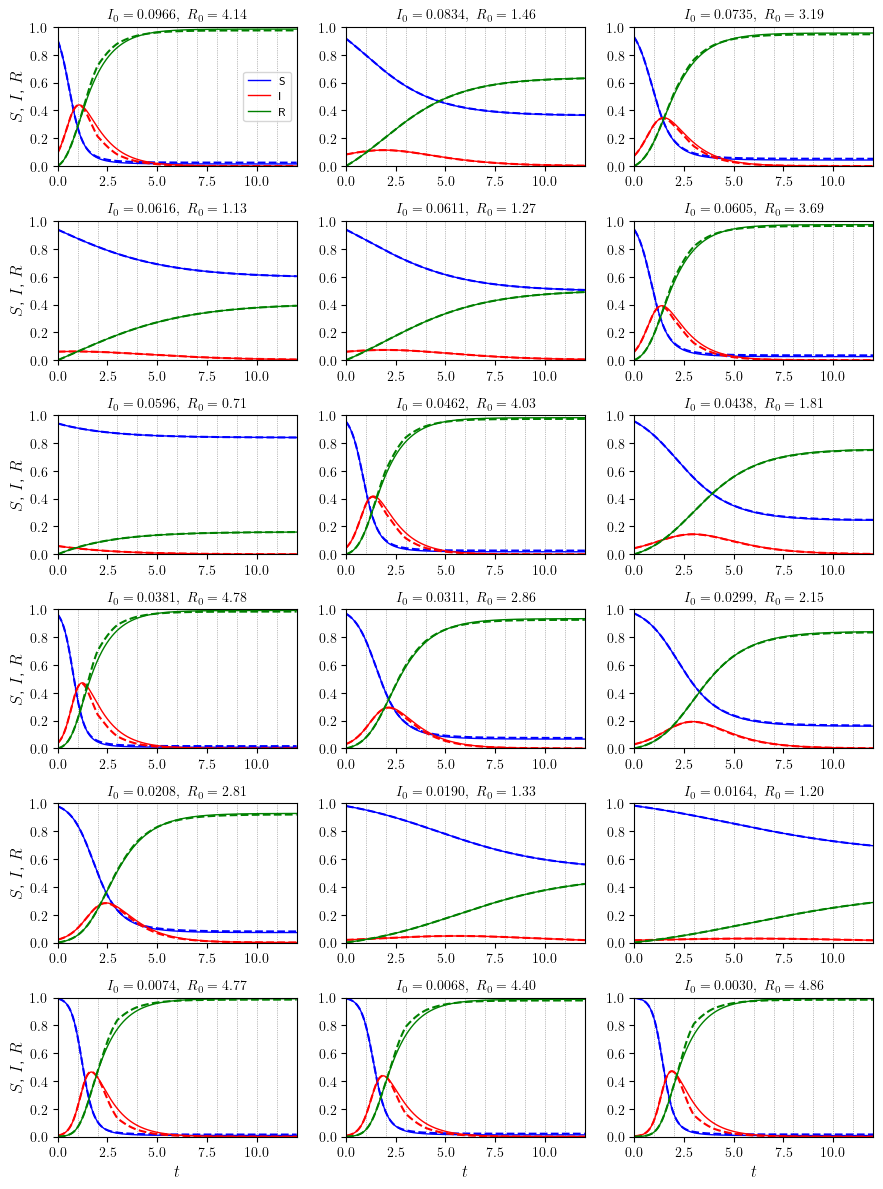

In [13]:
def plot_results(sol, exact, K=18,
                 ymin=0, ymax=1,
                 filename='results_march.png',
                 ftsize=12):

    plt.rcParams.update({'font.size': 10})

    ncols = 3
    nrows = K // ncols

    # sort selected points by decreasing I0 (as in tutorial_PINN_SIR_y)
    I0  = sol['I'][:K, 0]
    R_0 = sol['R_0'][:K]
    order = np.argsort(-I0)

    fgsize= (3*ncols, 2*nrows)
    fig = plt.figure(figsize=fgsize)

    colors = ['blue', 'red', 'green']
    labels = ['S', 'I', 'R']
    t = sol['t']

    for i, m in enumerate(order):

        ax  = fig.add_subplot(nrows, ncols, i+1)

        ax.set_xlim(t[0], t[-1])
        ax.set_ylim(ymin, ymax)

        if i >= (nrows-1) * ncols:
            ax.set_xlabel(r'$t$', fontsize=ftsize)

        if i % ncols == 0:
            ax.set_ylabel(r'$S$, $I$, $R$', fontsize=ftsize)

        ax.set_title(r'$I_0 = %6.4f,\ R_0 = %4.2f$' % (I0[m], R_0[m]), fontsize=10)

        # restarts
        for tk in np.arange(dt, t[-1], dt):
            ax.axvline(tk, color='gray', linestyle='dotted', linewidth=0.5)

        # RK45 (solid) and PINN (dashed)
        for k, key in enumerate(labels):
            ax.plot(t, exact[key][m], color=colors[k], linestyle='solid',
                    linewidth=1.0, label=key if i == 0 else None)
            ax.plot(t, sol[key][m], color=colors[k], linestyle='dashed',
                    linewidth=1.5)
        if i == 0:
            ax.legend(fontsize=8, loc='center right')

    fig.tight_layout()
    plt.savefig(filename)
    plt.show()

plot_results(pinn_march, exact)

## How does the accuracy degrade?
The left panel shows the error as a function of $t$: the median (solid) and 90% quantile (band) over the $M$ test points, together with a few individual test points (faint). The right panel shows the drift of $Q$. Both use a log scale so that the effect of each restart is visible.

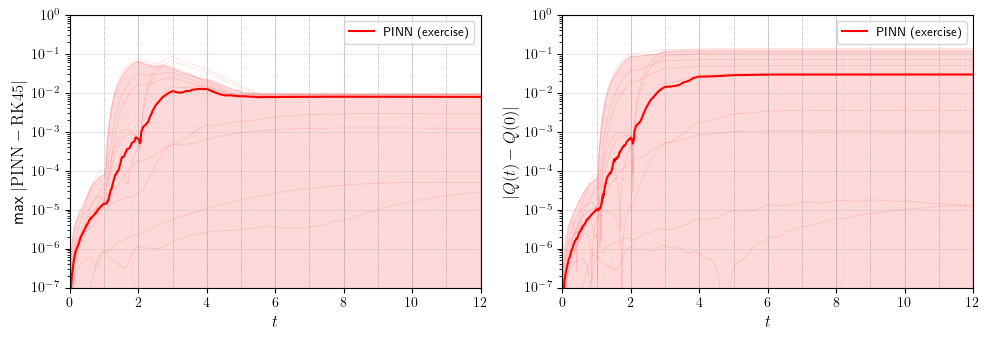

In [14]:
def plot_error_vs_t(curves, filename='error_vs_t.png', ftsize=12, n_faint=10):
    """curves: list of (label, color, err, dQ)"""

    plt.rcParams.update({'font.size': 10})
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

    for ax, j, ylabel in zip(axes, [2, 3],
                             [r'max $|\rm PINN - RK45|$', r'$|Q(t) - Q(0)|$']):
        for label, color, *arrays in curves:
            a = arrays[j - 2]
            for m in range(n_faint):
                ax.plot(t_grid, a[m], color=color, alpha=0.15, linewidth=0.5)
            ax.fill_between(t_grid, 1e-12, np.quantile(a, 0.9, axis=0),
                            color=color, alpha=0.15)
            ax.plot(t_grid, np.median(a, axis=0), color=color, label=label)
        for tk in np.arange(dt, tmax, dt):
            ax.axvline(tk, color='gray', linestyle='dotted', linewidth=0.5)
        ax.set_yscale('log')
        ax.set_ylim(1e-7, 1)
        ax.set_xlim(0, tmax)
        ax.set_xlabel(r'$t$', fontsize=ftsize)
        ax.set_ylabel(ylabel, fontsize=ftsize)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)

    fig.tight_layout()
    plt.savefig(filename)
    plt.show()

t_grid = pinn_march['t']
plot_error_vs_t([('PINN (exercise)', 'red', pinn_err, pinn_dQ)])

## Accumulation versus extrapolation
To separate the two effects we compute, for each step $k$, two errors over the segment $[t_k, t_k + \Delta t]$:
  * **global** error: from the marched solution, which starts from the PINN's own (slightly wrong) state at $t_k$;
  * **local** (one-step) error: the PINN applied *once*, starting from the *exact* state at $t_k$.

The local error measures how well the network does each step on its own. The gap between the global and local errors is what the recursion adds. We also record whether each restart $(I_0^\prime, R_0^\prime)$ lies inside the training domain.

In [15]:
def local_errors(soln, p, exact, tmax=tmax, dt=dt, nt=nt):
    """
    One PINN step from the exact state at each t_k.
    Returns: local error of shape (M, n_steps) and restart parameters.
    """
    n_steps = int(round(tmax / dt))
    tau = torch.linspace(0, dt, nt, dtype=torch.float64)
    Mp  = len(p)
    i_k = np.arange(n_steps) * (nt - 1)     # grid index of each t_k

    # exact states at all restarts, flattened to shape (M * n_steps,)
    S = torch.tensor(exact['S'][:, i_k].reshape(-1))
    I = torch.tensor(exact['I'][:, i_k].reshape(-1))
    R_0 = p[:, 1].double().repeat_interleave(n_steps)

    St, It, I0p, R0p = pinn_step(soln, S, I, R_0, tau)
    St = St.numpy().reshape(Mp, n_steps, nt)
    It = It.numpy().reshape(Mp, n_steps, nt)

    # exact solution on each segment: shape (M, n_steps, nt)
    seg = i_k[:, None] + np.arange(nt)[None, :]
    eS, eI = exact['S'][:, seg], exact['I'][:, seg]

    err = np.max([np.abs(St - eS), np.abs(It - eI),
                  np.abs((1 - St - It) - (1 - eS - eI))], axis=0).max(axis=2)
    return err, I0p.numpy().reshape(Mp, n_steps), R0p.numpy().reshape(Mp, n_steps)


def global_errors(err, tmax=tmax, dt=dt, nt=nt):
    """Maximum of the marched error over each segment: shape (M, n_steps)."""
    n_steps = int(round(tmax / dt))
    return np.array([err[:, k*(nt-1):(k+1)*(nt-1)+1].max(axis=1)
                     for k in range(n_steps)]).T


def in_domain(I0p, R0p, I0_lo, I0_hi, R_0_lo, R_0_hi):
    return (I0p >= I0_lo) & (I0p <= I0_hi) & (R0p >= R_0_lo) & (R0p <= R_0_hi)

pinn_local, pinn_I0p_exact, pinn_R0p_exact = local_errors(pinn, p_test, exact)
pinn_global = global_errors(pinn_err)

# restarts actually visited by the marched PINN (k = 0 is the initial state)
inside = in_domain(pinn_march['I0p'], pinn_march['R0p'],
                   I0_min, I0_max, R_0_min, R_0_max)

print(f'fraction of restarts inside the training domain: {inside.mean():.2f}')
print(f'  I0\' range: [{pinn_march["I0p"].min():.1e}, {pinn_march["I0p"].max():.2f}]')
print(f'  R0\' range: [{pinn_march["R0p"].min():.3f}, {pinn_march["R0p"].max():.2f}]')

fraction of restarts inside the training domain: 0.31
  I0' range: [8.7e-05, 0.83]
  R0' range: [0.064, 4.96]


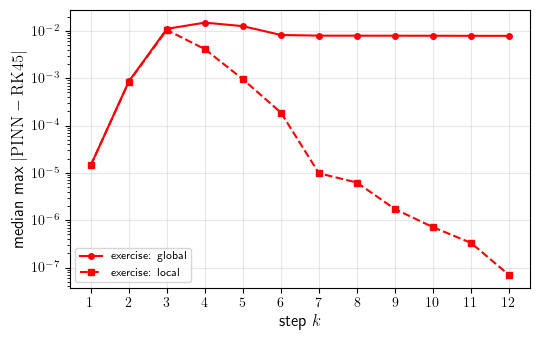

In [16]:
def plot_local_global(rows, filename='local_global.png', ftsize=12):
    """rows: list of (label, color, local, global)"""

    plt.rcParams.update({'font.size': 10})
    fig = plt.figure(figsize=(5.5, 3.5))
    ax  = fig.add_subplot(1, 1, 1)
    k = np.arange(1, n_steps_march + 1)
    for label, color, loc, glo in rows:
        ax.plot(k, np.median(glo, axis=0), color=color, marker='o',
                markersize=4, label=f'{label}: global')
        ax.plot(k, np.median(loc, axis=0), color=color, marker='s',
                markersize=4, linestyle='dashed', label=f'{label}: local')
    ax.set_yscale('log')
    ax.set_xlabel(r'step $k$', fontsize=ftsize)
    ax.set_ylabel(r'median max $|\rm PINN - RK45|$', fontsize=ftsize)
    ax.set_xticks(k)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.savefig(filename)
    plt.show()

plot_local_global([('exercise', 'red', pinn_local, pinn_global)])

### Where do the restarts land?
Each dot is a restart $(I_0^\prime, R_0^\prime)$ taken from the *exact* solution, colored by the local (one-step) error of the PINN. The red box is the training domain of `tutorial_PINN_SIR_y`; the dashed box is the widened domain of the optional section below.

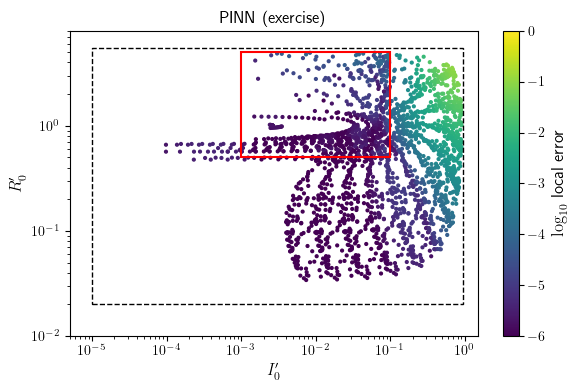

median local error, restarts inside  training domain: 2.1e-06
median local error, restarts outside training domain: 2.2e-05


In [17]:
# widened domain (used in the optional section below)
I0_min_w, I0_max_w   = 1e-5, 0.95
R_0_min_w, R_0_max_w = 0.02, 5.5

def plot_restarts(I0p, R0p, local, title='', filename='restarts.png', ftsize=12):

    plt.rcParams.update({'font.size': 10})
    fig = plt.figure(figsize=(6, 4))
    ax  = fig.add_subplot(1, 1, 1)

    sc = ax.scatter(I0p.ravel(), R0p.ravel(), c=np.log10(local.ravel()),
                    s=4, cmap='viridis', vmin=-6, vmax=0)
    cb = fig.colorbar(sc, ax=ax)
    cb.set_label(r'$\log_{10}$ local error', fontsize=ftsize)

    ax.add_patch(Rectangle((I0_min, R_0_min), I0_max - I0_min, R_0_max - R_0_min,
                           fill=False, edgecolor='red', linewidth=1.5))
    ax.add_patch(Rectangle((I0_min_w, R_0_min_w), I0_max_w - I0_min_w,
                           R_0_max_w - R_0_min_w,
                           fill=False, edgecolor='black', linestyle='dashed'))
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(5e-6, 1.5)
    ax.set_ylim(0.01, 8)
    ax.set_xlabel(r"$I_0^\prime$", fontsize=ftsize)
    ax.set_ylabel(r"$R_0^\prime$", fontsize=ftsize)
    ax.set_title(title, fontsize=ftsize)
    fig.tight_layout()
    plt.savefig(filename)
    plt.show()

plot_restarts(pinn_I0p_exact, pinn_R0p_exact, pinn_local,
              title='PINN (exercise)', filename='restarts_exercise.png')

inside_exact = in_domain(pinn_I0p_exact, pinn_R0p_exact,
                         I0_min, I0_max, R_0_min, R_0_max)
print(f'median local error, restarts inside  training domain: '
      f'{np.median(pinn_local[inside_exact]):.1e}')
print(f'median local error, restarts outside training domain: '
      f'{np.median(pinn_local[~inside_exact]):.1e}')

## Summary
For each step $k$, the median, 90% quantile, and worst value, over the $M$ test points, of the global error on the segment $[t_{k-1}, t_k]$.

In [18]:
def summary(glo, label):
    k = np.arange(1, glo.shape[1] + 1)
    return pd.DataFrame({'t': k * dt,
                         f'{label} median': np.median(glo, axis=0),
                         f'{label} 90%': np.quantile(glo, 0.9, axis=0),
                         f'{label} worst': glo.max(axis=0)}).set_index('t')

pd.options.display.float_format = '{:9.2e}'.format
summary(pinn_global, 'exercise')

,exercise median,exercise 90%,exercise worst
t,,,
1.00e+00,1.44e-05,8.08e-05,2.06e-04
2.00e+00,8.55e-04,6.50e-02,9.77e-02
3.00e+00,1.10e-02,7.16e-02,9.77e-02
4.00e+00,1.49e-02,4.24e-02,8.54e-02
5.00e+00,1.26e-02,2.22e-02,4.16e-02
6.00e+00,8.19e-03,1.09e-02,1.93e-02
7.00e+00,7.93e-03,9.44e-03,1.14e-02
8.00e+00,7.92e-03,9.39e-03,9.80e-03
9.00e+00,7.90e-03,9.35e-03,9.77e-03


## Optional: retrain on the widened domain
The restarts above visit parameters far outside the original training domain. Here we train the *same* network, with the *same* ODE residual, loss, optimizer, and schedule as in `tutorial_PINN_SIR_y`, but on the widened domain
\begin{align}
    t & \in [0, 1], \\
    I_0 & \in [10^{-5}, 0.95], \\
    R_0 & \in [0.02, 5.5],
\end{align}
which covers every restart. Since $I_0$ and $R_0$ now each span more than two decades, we sample both **log-uniformly** and feed $\log_{10} I_0$ and $\log_{10} R_0$ to the network (`log_R0=True`).

The results are written to a *new* folder, `runs/wide`, so the `runs/exercise` folder is left untouched. Set `TRAIN_WIDE = False` to skip the training and use previously saved results. To use the network whose training was continued in `tutorial_PINN_SIR_y_wide_continue`, set `wide_dir = 'wide_cont'` and `TRAIN_WIDE = False`.

In [19]:
TRAIN_WIDE = True

# folder runs/<wide_dir> for the widened-domain network. To use the network
# from tutorial_PINN_SIR_y_wide_continue, set wide_dir = 'wide_cont' and
# TRAIN_WIDE = False.
wide_dir = 'wide'

dataset_size_exponent = 17
dataset_size = 2**dataset_size_exponent  # Sobol sample size
test_size    = 2**13                     # test sample size
val_size     = 2**11                     # validation sample size
batch_size   = 2**10

# sampling bounds for (t, log10(I0), log10(R_0))
lower_bounds = [0.0,     np.log10(I0_min_w),  np.log10(R_0_min_w)]
upper_bounds = [t_train, np.log10(I0_max_w),  np.log10(R_0_max_w)]

# the network inputs are (t, log10(I0), log10(R_0)), mapped to [-1, 1]
input_lo_w = [float(x) for x in lower_bounds]
input_hi_w = [float(x) for x in upper_bounds]

# name of model
name = 'sir'
dirname = wide_dir

# create new configuration
config_w = mlp.Config(name, dirname=dirname)

train_size = dataset_size - val_size

config_w('batch_size', batch_size)
config_w('train_size', train_size)
config_w('test_size',  test_size)
config_w('val_size',   val_size)

config_w('monitor_step',  100)  # monitor training every "n" iterations
config_w('delete', True)        # delete losses file before training, if True
config_w('frac', 0.015)         # save model if average loss decreases by more
                                # than frac percent

# a step comprises a given number of iterations
config_w('n_iters_per_step', 20_000)
config_w('n_steps', 8)          # number of training steps
config_w('n_iterations', config_w('n_steps') * config_w('n_iters_per_step'))

config_w('base_lr', 4e-4)       # initial learning rate
config_w('gamma', 0.80)         # learning rate scale factor

# save the configuration only if we train: otherwise an existing
# configuration file in runs/<wide_dir> would be overwritten
if TRAIN_WIDE:
    print(f'\nSave configuration to file {config_w("file/config")}\n')
    config_w.save()

print(config_w)


Save configuration to file runs/wide/sir_config.yaml

name: sir
file:
  losses: runs/wide/sir_losses.csv
  params: runs/wide/sir_params.pth
  init_params: runs/wide/sir_init_params.pth
  plots: runs/wide/sir_plots.png
  config: runs/wide/sir_config.yaml
batch_size: 1024
train_size: 129024
test_size: 8192
val_size: 2048
monitor_step: 100
delete: true
frac: 0.015
n_iters_per_step: 20000
n_steps: 8
n_iterations: 160000
base_lr: 0.0004
gamma: 0.8



### Data
Sample $(t, \log_{10} I_0, \log_{10} R_0)$ and then exponentiate the last two columns, so that the `Dataset`s hold $(t, I_0, R_0)$ exactly as in `tutorial_PINN_SIR_y`.

In [20]:
def to_linear(sample):
    sample = np.array(sample)
    sample[:, 1:] = 10**sample[:, 1:]
    return sample.astype(np.float32)

sobol_sample = to_linear(dat.SobolSample(lower_bounds, upper_bounds,
                                         num_points_exp=dataset_size_exponent))
uniform_sample = to_linear(dat.UniformSample(lower_bounds, upper_bounds,
                                             num_points=val_size + test_size))

print(f'I0  range: [{sobol_sample[:, 1].min():.2e}, {sobol_sample[:, 1].max():.2e}]')
print(f'R_0 range: [{sobol_sample[:, 2].min():.2e}, {sobol_sample[:, 2].max():.2e}]')

print('training data')
train_data = dat.Dataset(sobol_sample, start=0, end=train_size,
                         split_col=1, requires_grad=True)

print('training data for validation')
train_data_val = dat.Dataset(sobol_sample, start=0, end=train_size,
                             split_col=1, requires_grad=True,
                             random_sample_size=val_size)

print('validation data')
val_data = dat.Dataset(uniform_sample, start=0, end=val_size,
                       split_col=1, requires_grad=True)

print('train data loader')
train_loader = dat.DataLoader(train_data,
                              batch_size=config_w('batch_size'),
                              num_iterations=config_w('n_iterations'))

print('train data loader for validation')
train_loader_val = dat.DataLoader(train_data_val, batch_size=len(train_data_val))

print('validation data loader')
val_loader  = dat.DataLoader(val_data, batch_size=len(val_data))

SobolSample
  131072 Sobol points created in unit 3-cube.
UniformSample
  10240 uniformly sampled points created in unit 3-cube.
I0  range: [1.00e-05, 9.50e-01]
R_0 range: [2.00e-02, 5.50e+00]
training data
Dataset
  shape of x: torch.Size([129024, 1])
  shape of y: torch.Size([129024, 2])

training data for validation
Dataset
  shape of x: torch.Size([2048, 1])
  shape of y: torch.Size([2048, 2])

validation data
Dataset
  shape of x: torch.Size([2048, 1])
  shape of y: torch.Size([2048, 2])

train data loader
DataLoader
  Number of iterations has been specified
  maxiter:          160000
  batch_size:         1024
  shuffle_step:        126

train data loader for validation
DataLoader
  maxiter:               1
  batch_size:         2048
  shuffle_step:          1

validation data loader
DataLoader
  maxiter:               1
  batch_size:         2048
  shuffle_step:          1



### Objective function and training
Same as in `tutorial_PINN_SIR_y`:
\begin{align}
    \text{residuals} & = \ddot{y} + R_0 \, \exp(y) \, (\dot{y} + 1) .
\end{align}

In [21]:
class Objective(mlp.Model):
    """
    Define the ODE-based average loss for the PINN.
    Computes the ODE residuals and returns the mean
    squared residuals.
    """
    def __init__(self, solution):
        super().__init__()
        self.solution = solution

    def eval(self):
        self.solution.eval()
        return self

    def train(self, mode=True):
        self.solution.train(mode)
        return self

    def forward(self, t, p):
        # Assumes inputs come with shape (batch_size, D)
        y = self.solution(t, p)

        # First derivative dy/dt
        doty = torch.autograd.grad(
            y, t,
            grad_outputs=torch.ones_like(y),
            create_graph=True
        )[0]

        # Second derivative d^2y/dt^2
        ddoty = torch.autograd.grad(
            doty, t,
            grad_outputs=torch.ones_like(doty),
            create_graph=True
        )[0]

        # Residuals of the ODE
        # ddot(y) + R_0 * exp(y) * (dot(y) + 1)
        R_0 = p[:, 1:2] # reproduction number

        residuals = ddoty + R_0 * torch.exp(y) * (doty + 1)

        return torch.mean(residuals**2)


def train(objective, optimizer, scheduler, monitor,
          train_loader, train_small_loader, val_loader):

    monitor.start()

    for t, p in train_loader:

        # set mode to training so that training-specific
        # operations such as dropout, etc., are enabled.
        objective.train()

        # clear all gradients
        optimizer.zero_grad()

        # compute empirical risk
        R = objective(t, p)

        # compute gradients
        R.backward()

        # take one step downhill in the empirical risk landscape
        optimizer.step()

        # check whether to update learning rate
        scheduler.step()

        # I'm alive printout
        if monitor.step():

            # compute average losses on training and validation data
            t_loss = mlp.compute_avg_loss(objective, train_small_loader)
            v_loss = mlp.compute_avg_loss(objective, val_loader)

            # return current learning rate
            lr = scheduler.lr()

            # update loss file
            monitor(t_loss, v_loss, lr)

    monitor.terminate(5)

In [22]:
gnet_w     = mlp.FCNN(n_inputs=3, n_hidden=3, n_width=64, n_outputs=1,
                      f_hidden=mlp.Sin()).to(DEVICE)

solution_w = Solution(gnet_w, input_lo_w, input_hi_w, log_R0=True).to(DEVICE)

objective_w = Objective(solution_w).to(DEVICE)

optimizer_w = torch.optim.Adam(solution_w.parameters(), lr=config_w('base_lr'))

scheduler_w = mlp.LRStepScheduler(
    optimizer_w,
    n_steps=config_w('n_steps'),
    n_iters_per_step=config_w('n_iters_per_step'),
    base_lr=config_w('base_lr'),
    gamma=config_w('gamma')
)

# Note: with newlossfile=True, Monitor empties the loss file as soon as it
# is created, so create it only if we train.
if TRAIN_WIDE:
    monitor_w = mon.Monitor(
        config_w('n_iterations'),
        config_w('file/losses'),
        monitorstep=config_w('monitor_step'),
        newlossfile=True,
        frac=config_w('frac'),
        model=solution_w,
        paramsfile=config_w('file/params'))

print(solution_w)

print(f'Number of parameters: {mlp.number_of_parameters(solution_w)}')

number of milestones:          7

Step | Milestone | LR
-----------------------------
   0 |         0 | 4.0e-04   
-----------------------------
   1 |     20000 | 3.2e-04   
   2 |     40000 | 2.6e-04   
   3 |     60000 | 2.0e-04   
   4 |     80000 | 1.6e-04   
   5 |    100000 | 1.3e-04   
   6 |    120000 | 1.0e-04   
   7 |    140000 | 8.4e-05   

Solution(
  (g): FCNN(
    (f_hidden): Sin()
    (net): Sequential(
      (0): Linear(in_features=3, out_features=64, bias=True)
      (1): Sin()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Sin()
      (4): Linear(in_features=64, out_features=64, bias=True)
      (5): Sin()
      (6): Linear(in_features=64, out_features=1, bias=True)
    )
  )
)
Number of parameters: 8641


monlosses runs/wide/sir_losses.csv

		learning rate:  4.000e-04
     19900| 12.44%|00:06:57|00:48:58|  47.7 it/s|3.034e-04|2.497e-04|     19900|
		learning rate:  3.200e-04
     39900| 24.94%|00:14:04|00:42:22|  47.2 it/s|1.102e-04|7.065e-05|     39900|
		learning rate:  2.560e-04
     59900| 37.44%|00:21:31|00:35:57|  46.4 it/s|6.220e-05|5.297e-05|     59900|
		learning rate:  2.048e-04
     79900| 49.94%|00:28:35|00:28:40|  46.6 it/s|3.477e-05|2.975e-05|     79900|
		learning rate:  1.638e-04
     99900| 62.44%|00:35:41|00:21:28|  46.7 it/s|5.111e-05|6.966e-05|     99900|
		learning rate:  1.311e-04
    119900| 74.94%|00:42:47|00:14:18|  46.7 it/s|1.759e-05|2.805e-05|    119900|
		learning rate:  1.049e-04
    139900| 87.44%|00:49:56|00:07:10|  46.7 it/s|3.054e-05|2.763e-05|    139900|
		learning rate:  8.389e-05
    159900| 99.94%|00:57:07|00:00:02|  46.7 it/s|1.168e-05|1.658e-05|    159900|
	Terminating standalone loss monitor...
	Done!


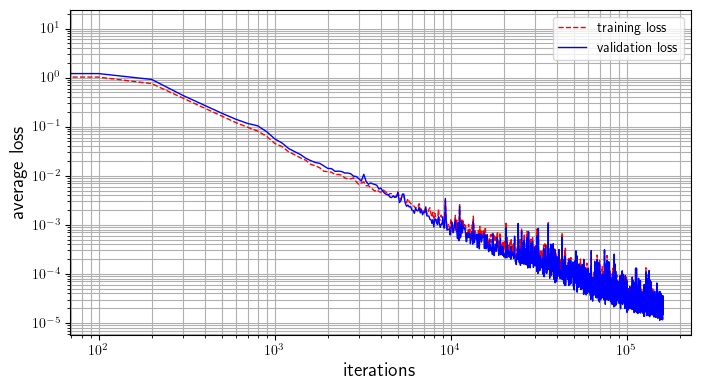

In [23]:
if TRAIN_WIDE:

    train(objective_w, optimizer_w, scheduler_w, monitor_w,
          train_loader, train_loader_val, val_loader)

    mon.plot_losses(config_w('file/losses'))

## Comparison: original versus widened domain
March the same $M$ test points with the PINN trained on the widened domain and repeat the diagnostics.

In [24]:
pinn_w = load_pinn(f'runs/{wide_dir}/sir_config.yaml', log_R0=True)

wide_march = march(lambda S, I, R_0, tau: pinn_step(pinn_w, S, I, R_0, tau), p_test)

wide_err, wide_dQ = errors(wide_march, exact)
wide_local, wide_I0p_exact, wide_R0p_exact = local_errors(pinn_w, p_test, exact)
wide_global = global_errors(wide_err)

inside_w = in_domain(wide_march['I0p'], wide_march['R0p'],
                     I0_min_w, I0_max_w, R_0_min_w, R_0_max_w)
print(f'fraction of restarts inside the widened domain: {inside_w.mean():.2f}')

loaded runs/wide/sir_params.pth
  input lower bounds: [[ 0.      -5.      -1.69897]]
  input upper bounds: [[ 1.         -0.02227639  0.7403627 ]]
fraction of restarts inside the widened domain: 1.00


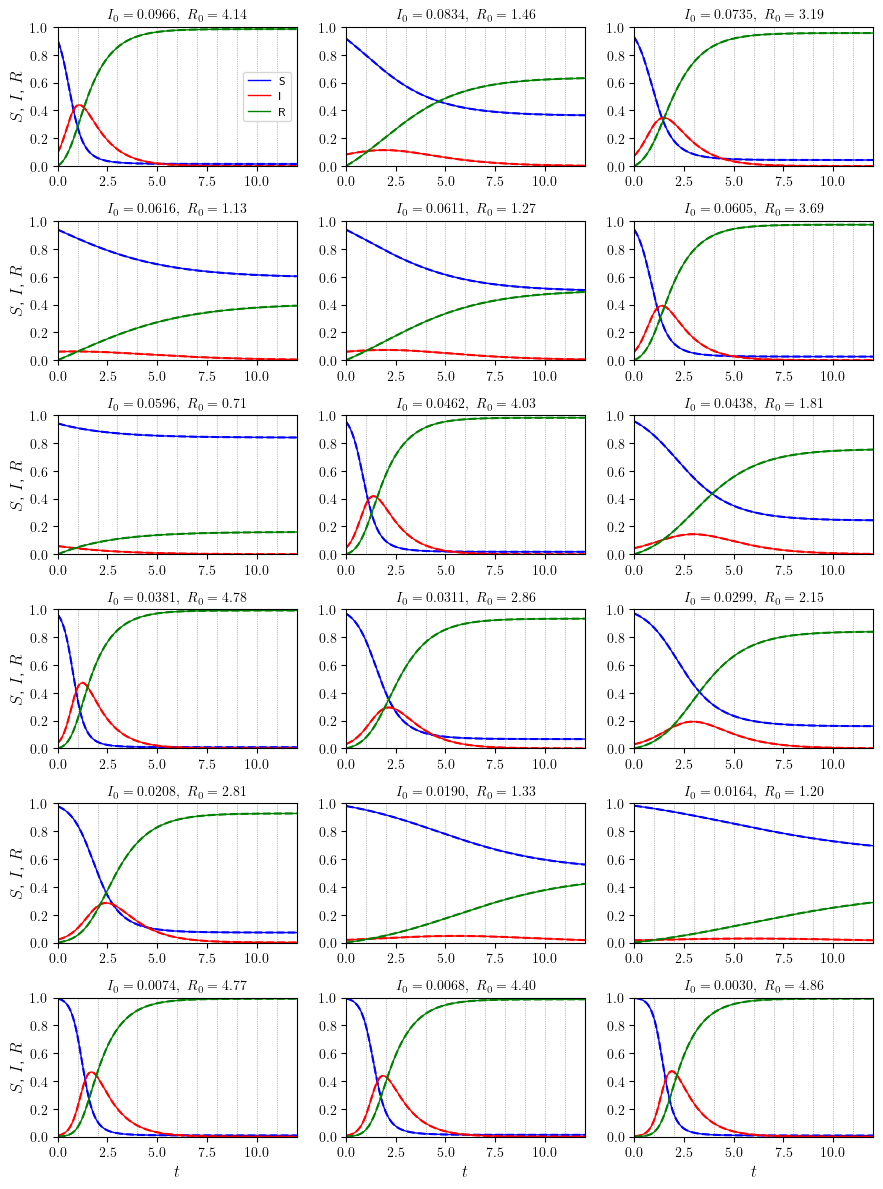

In [25]:
plot_results(wide_march, exact, filename='results_march_wide.png')

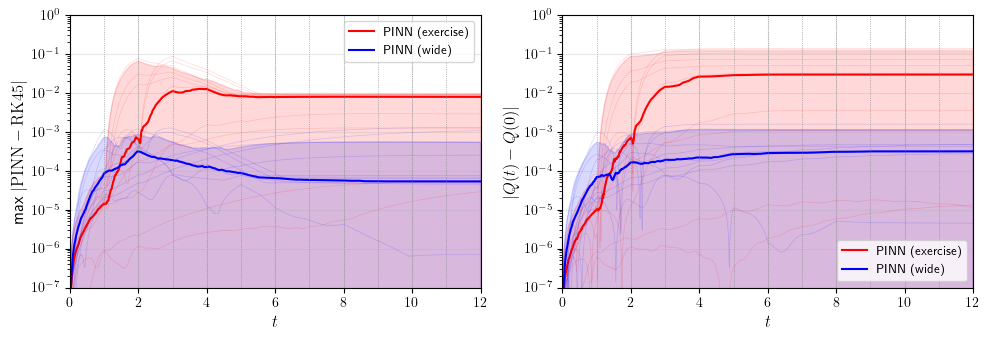

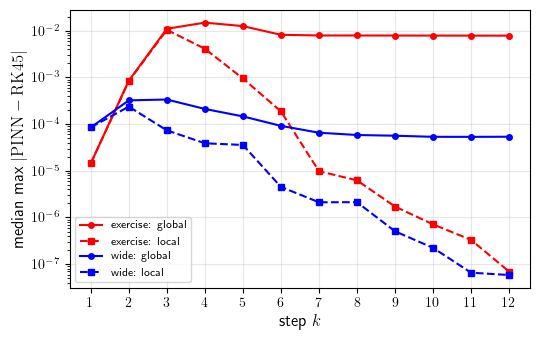

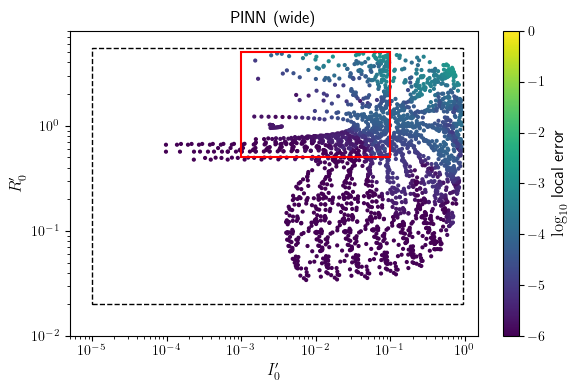

In [26]:
plot_error_vs_t([('PINN (exercise)', 'red',  pinn_err, pinn_dQ),
                 ('PINN (wide)',     'blue', wide_err, wide_dQ)],
                filename='error_vs_t_compare.png')

plot_local_global([('exercise', 'red',  pinn_local, pinn_global),
                   ('wide',     'blue', wide_local, wide_global)],
                  filename='local_global_compare.png')

plot_restarts(wide_I0p_exact, wide_R0p_exact, wide_local,
              title='PINN (wide)', filename='restarts_wide.png')

In [27]:
pd.concat([summary(pinn_global, 'exercise'), summary(wide_global, 'wide')], axis=1)

,exercise median,exercise 90%,exercise worst,wide median,wide 90%,wide worst
t,,,,,,
1.00e+00,1.44e-05,8.08e-05,2.06e-04,8.51e-05,7.15e-04,1.61e-03
2.00e+00,8.55e-04,6.50e-02,9.77e-02,3.23e-04,9.88e-04,1.61e-03
3.00e+00,1.10e-02,7.16e-02,9.77e-02,3.36e-04,1.02e-03,1.29e-03
4.00e+00,1.49e-02,4.24e-02,8.54e-02,2.11e-04,5.49e-04,1.24e-03
5.00e+00,1.26e-02,2.22e-02,4.16e-02,1.46e-04,4.58e-04,6.40e-04
6.00e+00,8.19e-03,1.09e-02,1.93e-02,9.17e-05,5.00e-04,7.97e-04
7.00e+00,7.93e-03,9.44e-03,1.14e-02,6.54e-05,5.31e-04,9.60e-04
8.00e+00,7.92e-03,9.39e-03,9.80e-03,5.85e-05,5.44e-04,1.11e-03
9.00e+00,7.90e-03,9.35e-03,9.77e-03,5.64e-05,5.49e-04,1.25e-03


## Exercises
  1. Halve the step, `dt = 0.5`, so that each step uses only half of the training interval. How do the local and global errors change? Why might a shorter step help even though it doubles the number of restarts?
  2. Is there evidence that errors *grow* from step to step, or merely *add up*? (*Hint*: compare the global error with the cumulative sum of local errors.)
  3. Increase `tmax` to 24. What happens to the restart parameters $(I_0^\prime, R_0^\prime)$ late in the epidemic, and does the widened domain still cover them?